# Section 2 · E4 training, checks and logs

Chris's part of the notebook: the E4 training runs, the A2-a evaluation run, the validation checks, the training curves and the environment record.

**Not in this notebook (Section 3, Zhihao):** the ablation results tables (paired McNemar, Table 2), the test-set evaluation, the baselines and the main results table.

**Rules from the plan (§0, §4).** Validation only. Every result uses seeds 4012, 4013, 4014. Each training ablation changes **one** setting; everything else equals the frozen E2 configuration. A2-a re-evaluates the trained checkpoints without retraining.


## How to use this notebook (for markers)

- **Default (`RUN_TRAINING = False`)**: nothing is retrained. The notebook reads the saved logs in the repository (`experiments/E2/results/final_3seed/` for the main model, `experiments/E4 updated/e4_logs/` for the ablations), checks them, and writes the tables and the figure to `experiments/E4 updated/`. No GPU, no Google Drive and no internet are needed. Run it from the root of the downloaded repository.
- **Training (`RUN_TRAINING = True`)**: the original Colab procedure on a T4 GPU, with checkpoints on Google Drive. About 16 minutes per run, about 50 minutes per ablation. It is not needed for marking.
- **Outputs**: every table is saved as a CSV and the figure as a PNG. The figure is drawn from the saved per-epoch history files, not from in-memory data, so it can be redrawn from the repository alone.
- **Model weights**: the `best.pt` checkpoints are not in the repository (size). Markers do not need them, because every number here comes from the saved logs.
- **Weights.** The main model's three checkpoints are in `experiments/E2/checkpoints/` (state_dict, can be loaded without retraining). The ablation checkpoints were produced on Colab and are not in this repository. Nothing in the default mode needs them; see `README4.md`.


In [1]:
# ---- Configuration: every hyperparameter and run setting used in this notebook ----
RUN_TRAINING = False          # False (default, for markers): read the saved logs. True: retrain on Colab (T4).
SEEDS = [4012, 4013, 4014]    # seeds for the main model (E2) and every ablation; fixed so runs are repeatable
MAX_EPOCHS = 300              # training budget, no early stopping (frozen E2 setting)
EXPECTED_VALID_ROWS = 1606
# Data split used by the E2 and E4 runs (record only; the data pipeline is documented elsewhere).
# Train and validation sizes are from the E2 log; the validation size is checked against the saved predictions in 2.2b.
# The test size is from the README only; the test split is not used in this notebook.
SPLIT = {'method': 'piqa_to_dataframe, grouped by goal, seed 4012', 'train': 14507, 'valid': 1606, 'test': 1838}    # size of the validation split (plan section 0); the test split is not used here

# Key settings used by the checks in section 2.2.
MAIN_EXPECTED = {
    'optimizer': 'adamw', 'learning_rates': [0.0009], 'weight_decay': 0.01, 'dropout_rate': 0.3,
    'num_layers': 2, 'num_heads': 4, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'pooling': 'cls', 'enable_pos_emb': True, 'batch_size': 512, 'max_epochs': 300,
}

# Frozen main model: every setting of the E2 run (E2 _commit d0268525). Written here, not read from a file.
FROZEN = {
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model', 'models': ['transformer'],
    'learning_rates': [0.0009], 'seeds': [4012, 4013, 4014], 'optimizer': 'adamw',
    'weight_decay': 0.01, 'momentum': 0.9, 'batch_size': 512, 'max_epochs': 300, 'patience': None,
    'grad_clip': None, 'num_workers': 2, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'num_heads': 4, 'num_layers': 2, 'dropout_rate': 0.3, 'pooling': 'cls',
    'enable_pos_emb': True, '_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7',
}

# Ablations: each entry changes exactly one setting from the frozen model.
ABLATIONS = {
    'a1_no_position':  {'enable_pos_emb': False},   # A1'-a: no positional encoding
    'a1_one_head':     {'num_heads': 1},            # A1'-b: one attention head instead of four
    'a1_mean_pooling': {'pooling': 'mean'},         # A1'-c: optional, not run
    'a3_no_dropout':   {'dropout_rate': 0.0},       # A3: dropout 0 instead of 0.3
}
CHOSEN = ['a1_no_position', 'a1_one_head']   # team decision: A1'-a and A1'-b
# A2-a (goal removed at evaluation) is set in section 2.5 and uses the same seeds.

## 2.1 · Setup

Find the repository and set the run mode. Read mode (default, for markers) uses the downloaded repository and needs no GPU or Drive. Training mode (Colab) mounts Drive, checks the GPU and clones the `baselines` branch. The commit used is recorded in every output.

In [2]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def git(*args):
    return subprocess.check_output(['git', '-C', str(REPO), *args], text=True).strip()

if RUN_TRAINING:
    # Colab: clone the baselines branch, mount Drive, require a T4 GPU.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)
    from google.colab import drive
    drive.mount('/content/drive')

    import torch
    assert torch.cuda.is_available(), 'Runtime > Change runtime type > T4 GPU, then rerun.'
    print(torch.cuda.get_device_name(0))

    REPO = Path('/content/repo')
    if not (REPO / '.git').exists():
        subprocess.run(['git', 'clone', '-q', '-b', 'baselines',
                        'https://github.com/RayYouDS/cits4012-NLP-project.git', str(REPO)], check=True)
    # An old clone can sit on another branch, an older commit, or with local edits.
    assert git('rev-parse', '--abbrev-ref', 'HEAD') == 'baselines', 'Delete /content/repo and rerun.'
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', 'origin', 'baselines'], check=True)
    assert git('rev-parse', 'HEAD') == git('rev-parse', 'FETCH_HEAD'), 'Clone is not at origin/baselines. Delete /content/repo and rerun.'
    assert git('status', '--porcelain', '--untracked-files=no') == '', 'Tracked files in /content/repo are edited. Delete it and rerun.'

    E2_DIR = Path('/content/drive/MyDrive/cits4012/e2_full_300/final_3seed')   # checkpoints live here
    E4_DIR = Path('/content/drive/MyDrive/cits4012/e4_full')                   # training output
    OUT_DIR = E4_DIR
else:
    # Markers: run from the downloaded repository (the folder that contains experiments/).
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
    E2_DIR = REPO / 'experiments/E2/results/final_3seed'   # saved main-model logs
    E4_DIR = REPO / 'experiments/E4 updated/e4_logs'                  # saved ablation logs
    OUT_DIR = REPO / 'experiments/E4 updated'                      # training summary and figure are written here
    print('repository folder:', REPO.name)

HAS_GIT = (REPO / '.git').exists()
E4_COMMIT = git('rev-parse', 'HEAD') if HAS_GIT else 'not recorded (no .git in this copy)'
print('mode:', 'training' if RUN_TRAINING else 'read saved logs', '| commit:', E4_COMMIT[:9])

repository folder: repo
mode: read saved logs | commit: not recor


## 2.2 · The frozen E2 configuration

These are the settings every ablation inherits. Only the three seeds and the E2 folder are fixed here; everything else comes from `config.json`.


In [3]:
# Check the frozen settings against the saved record of the main run (a data file, not a settings source).
saved_main = json.loads((E2_DIR / 'config.json').read_text(encoding='utf-8'))
for k, v in FROZEN.items():
    if not k.startswith('_') and k != 'output_dir':
        assert saved_main.get(k) == v, f'{k}: saved run has {saved_main.get(k)}, notebook has {v}'
assert saved_main['_commit'] == FROZEN['_commit'], 'saved run commit differs from the notebook'

assert FROZEN['models'] == ['transformer']
assert FROZEN['max_epochs'] == MAX_EPOCHS
assert sorted(FROZEN['seeds']) == SEEDS
assert len(FROZEN['learning_rates']) == 1
assert FROZEN['dropout_rate'] != 0.0, 'Main model has dropout 0, so A3 needs a different comparison.'

LR = FROZEN['learning_rates'][0]
E2_COMMIT = FROZEN['_commit']

pd.Series({k: FROZEN[k] for k in ['optimizer', 'learning_rates', 'weight_decay', 'dropout_rate',
                                  'num_layers', 'num_heads', 'pooling', 'enable_pos_emb',
                                  'batch_size', 'max_epochs', 'patience']}, name='frozen E2')


optimizer            adamw
learning_rates    [0.0009]
weight_decay          0.01
dropout_rate           0.3
num_layers               2
num_heads                4
pooling                cls
enable_pos_emb        True
batch_size             512
max_epochs             300
patience              None
Name: frozen E2, dtype: object

**Provenance check.** E2 ran on commit `E2_COMMIT`. This notebook runs on `E4_COMMIT`. The comparison is valid only if the code the model depends on is unchanged between the two, so this check fails loudly if it is not. Changes to other files (docs, baseline scripts) are allowed.


In [4]:
E2_PATHS = ['scripts/training/', 'scripts/models/', 'scripts/data_loader/',
            'scripts/evaluation/', 'scripts/tokenizer/', 'datasets/']
if not HAS_GIT:
    print('No .git in this copy: the code check against E2 was made when the runs were recorded.')
else:
    changed = git('diff', '--name-only', E2_COMMIT, E4_COMMIT, '--', *E2_PATHS).split()
    assert not changed, f'Code used by E2 changed between {E2_COMMIT[:9]} and {E4_COMMIT[:9]}: {changed}'
    untracked = git('ls-files', '--others', '--exclude-standard', '--', *E2_PATHS)
    assert untracked == '', f'Untracked files in code used by E2: {untracked}'
    print(f'E2 code unchanged: {E2_COMMIT[:9]} -> {E4_COMMIT[:9]}')


No .git in this copy: the code check against E2 was made when the runs were recorded.


## 2.2b · Saved main-model weights

Check that the saved E2 weights for seed 4012 (the main model used by A2-a) load into the repository model class with the frozen settings. No training happens here. The split used by these runs is recorded in the configuration cell and checked against the saved predictions.


In [5]:
# Check the split size recorded in the configuration cell against the saved E2 predictions.
n_valid_pred = len(pd.read_csv(E2_DIR / f'm3_transformer_lr{LR:g}_seed4012_val_predictions.csv'))
assert n_valid_pred == SPLIT['valid'] == EXPECTED_VALID_ROWS, (n_valid_pred, SPLIT)
pd.DataFrame([
    {'split': 'train', 'rows': SPLIT['train'], 'used in this notebook': 'no (training happened in E2)'},
    {'split': 'validation', 'rows': SPLIT['valid'], 'used in this notebook': 'yes (all results)'},
    {'split': 'test', 'rows': SPLIT['test'], 'used in this notebook': 'no'},
]).set_index('split')

,rows,used in this notebook
split,,
train,14507,no (training happened in E2)
validation,1606,yes (all results)
test,1838,no


In [6]:
# Load the saved main-model weights (E2, seed 4012) into the repository's model class. No training.
import torch
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))          # relative imports from the downloaded repository
from scripts.models.transformer_bi_classifier import TransformerClassifier

model = TransformerClassifier(vocab_size=8000, embedding_dim=FROZEN['embedding_dim'], padding_idx=3,
                              max_seq_length=2048, num_heads=FROZEN['num_heads'], num_layers=FROZEN['num_layers'],
                              dropout_rate=FROZEN['dropout_rate'], pooling=FROZEN['pooling'],
                              enable_pos_emb=FROZEN['enable_pos_emb'])
CKPT_DIR = (REPO / 'experiments/E2/checkpoints') if not RUN_TRAINING else E2_DIR
ckpt = CKPT_DIR / f'm3_transformer_lr{LR:g}_seed4012_best.pt'
model.load_state_dict(torch.load(ckpt, map_location='cpu', weights_only=True), strict=True)
model.eval()
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_trainable == 933357, n_trainable   # model size in the E2 log; the positional table is a buffer and is not counted
print(f'loaded {ckpt.name}: {n_trainable:,} trainable parameters')

loaded m3_transformer_lr0.0009_seed4012_best.pt: 933,357 trainable parameters


**Reference: the E2 result for the frozen configuration.** These are the numbers every ablation is compared against.


In [7]:
e2 = pd.read_csv(E2_DIR / 'm3_summary.csv')
print(e2[['seed', 'valid_accuracy', 'best_epoch', 'gap_at_best']].to_string(index=False))
print(f"mean {e2.valid_accuracy.mean():.4f}, s.d. {e2.valid_accuracy.std():.4f}")


 seed  valid_accuracy  best_epoch  gap_at_best
 4012        0.599626         213     0.289539
 4013        0.597758         179     0.267746
 4014        0.584682         164     0.267123
mean 0.5940, s.d. 0.0081


## 2.3 · Choose the ablations

Each entry changes exactly one setting. The Transformer main model has 4 heads, CLS pooling and positional encoding on, so:
- `a1_no_position` removes positional encoding (A1′-a).
- `a1_one_head` changes 4 heads to 1 head (A1′-b).
- `a1_mean_pooling` changes CLS pooling to mean pooling (A1′-c).
- `a3_no_dropout` changes dropout 0.3 to 0 (A3).

**Team decision:** `CHOSEN` is set to `a1_no_position` (A1′-a, position information) and `a1_one_head` (A1′-b, one head vs four). `a1_mean_pooling` is not run. The notebook still checks that `CHOSEN` has one or two valid, non-duplicate rows. Record the choice and the reason in the report.


In [8]:
RUN_NAMES = CHOSEN + ['a3_no_dropout']
assert 1 <= len(CHOSEN) <= 2 and all(c in ('a1_no_position', 'a1_one_head', 'a1_mean_pooling') for c in CHOSEN), \
    'Set CHOSEN (configuration cell) to one or two A1′ rows (team decision) before running.'
assert len(CHOSEN) == len(set(CHOSEN)), 'CHOSEN lists the same ablation twice.'

def make_config(name):
    change = ABLATIONS[name]
    # One variable per ablation: the rule is on the declared change itself.
    assert len(change) == 1, f'{name} changes {len(change)} settings; an ablation changes exactly one.'
    cfg = {**FROZEN, **change, 'seeds': SEEDS, 'max_epochs': MAX_EPOCHS,
           'output_dir': str(E4_DIR / name), '_ablation': name, '_changes': change,
           '_base_commit': E2_COMMIT, '_commit': E4_COMMIT}
    cfg.pop('_from', None)
    # Nothing else may differ from the frozen configuration.
    differs = [k for k in FROZEN if not k.startswith('_') and k not in ('output_dir', 'seeds', 'max_epochs')
               and FROZEN[k] != cfg.get(k)]
    assert differs == list(change), f'{name} changes {differs}, expected {list(change)}'
    return cfg

for name in RUN_NAMES:
    cfg = make_config(name)
    print(f"{name:16s} changes {cfg['_changes']}")

a1_no_position   changes {'enable_pos_emb': False}
a1_one_head      changes {'num_heads': 1}
a3_no_dropout    changes {'dropout_rate': 0.0}


## 2.4 · Train the ablations

Each ablation is 3 seeds × 300 epochs, about 16 minutes per run on a T4, so about 50 minutes per ablation. Colab can disconnect mid-run, and a run that dies is not resumed. If a folder has files but no `m3_summary.csv`, delete that folder and rerun the cell.

A finished folder is **not** reused blindly. The checks below confirm that its configuration is this ablation on this E2 base, that the code it depends on has not changed since it ran, that all three seeds are complete, and that every history ends at epoch 300. Changes in other files (reports, figures, docs) do not force a rerun.


In [9]:
def final_epoch(folder, seed):
    h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
    last = h.iloc[-1]
    assert int(last['epoch']) == 300, f'{folder.name} seed {seed} ended at epoch {int(last["epoch"])}'
    return {'gap_at_end': float(last['train_eval_accuracy'] - last['valid_accuracy']),
            'valid_loss_at_end': float(last['valid_loss'])}

def check_training_folder(name):
    out = E4_DIR / name
    cfg = make_config(name)
    saved = json.loads((out / 'config.json').read_text(encoding='utf-8'))

    # 1. The saved configuration is this ablation, built on this E2 base.
    assert saved.get('_ablation') == name, f'{name}: saved _ablation is {saved.get("_ablation")}'
    assert saved.get('_base_commit') == E2_COMMIT, f'{name}: saved _base_commit is not the E2 commit'
    assert saved.get('_changes') == ABLATIONS[name], f'{name}: saved _changes differ'
    for k in cfg:
        if not k.startswith('_') and k != 'output_dir' and saved.get(k) != cfg[k]:
            raise RuntimeError(f'{name}: saved config differs on {k}: {saved.get(k)} vs {cfg[k]}')

    # 2. Code the experiment depends on has not changed since it ran.
    saved_commit = saved.get('_commit')
    if not saved_commit:
        raise RuntimeError(f'{name}: saved config has no _commit')
    if HAS_GIT:
        touched = git('diff', '--name-only', saved_commit, E4_COMMIT, '--', *E2_PATHS).split()
        if touched:
            raise RuntimeError(f'{name}: code used by this experiment changed: {touched}')
        if saved_commit != E4_COMMIT:
            print(name, 'reused: commit differs, but experiment-dependent code is unchanged')
    else:
        print(name, ': no .git in this copy, so the code check is skipped')

    # 3. Summary: right model, learning rate, budget, and all three seeds.
    summary = pd.read_csv(out / 'm3_summary.csv')
    assert set(summary['model']) == {'transformer'}, f'{name}: models {set(summary["model"])}'
    assert all(abs(x - LR) < 1e-12 for x in summary['learning_rate']), f'{name}: learning rates differ'
    assert set(summary['epochs_run']) == {300}, f'{name}: epochs_run {set(summary["epochs_run"])}'
    if sorted(summary['seed'].astype(int)) != SEEDS:
        raise RuntimeError(f'{name}: summary seeds are {sorted(summary["seed"])}, expected {SEEDS}')

    # 4. Every seed has history, validation predictions and the checkpoint;
    #    the history ends at epoch 300; the predictions cover the validation split.
    for seed in SEEDS:
        base = f'm3_transformer_lr{LR:g}_seed{seed}'
        # Checkpoints (best.pt) are on Drive only; read mode does not need them.
        for f in (f'{base}_history.csv', f'{base}_val_predictions.csv') + ((f'{base}_best.pt',) if RUN_TRAINING else ()):
            if not (out / f).exists():
                raise RuntimeError(f'{name}: missing {f}')
        if len(pd.read_csv(out / f'{base}_val_predictions.csv')) != EXPECTED_VALID_ROWS:
            raise RuntimeError(f'{name} seed {seed}: predictions do not cover the validation split')
        final_epoch(out, seed)
    return True

def train(name):
    cfg = make_config(name)
    out = E4_DIR / name
    if (out / 'm3_summary.csv').exists():
        check_training_folder(name)
        print(name, 'already finished and verified')
        return
    if not RUN_TRAINING:
        raise RuntimeError(f'{name}: no saved run in {out}. Copy the run folder into the repository, or set RUN_TRAINING = True on Colab.')
    partial = [p.name for p in out.glob('*') if p.name != 'config.json'] if out.exists() else []
    if partial:
        raise RuntimeError(f'{out} has partial files {partial[:4]} but no summary. Delete it and rerun.')
    out.mkdir(parents=True, exist_ok=True)
    cfg_path = out / 'config.json'
    cfg_path.write_text(json.dumps(cfg, indent=2), encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'scripts.training.run_m3', '--config', str(cfg_path)],
                   cwd=REPO, check=True)
    check_training_folder(name)
    print(name, 'done and verified')

for name in RUN_NAMES:
    train(name)

a1_no_position : no .git in this copy, so the code check is skipped
a1_no_position already finished and verified
a1_one_head : no .git in this copy, so the code check is skipped
a1_one_head already finished and verified
a3_no_dropout : no .git in this copy, so the code check is skipped
a3_no_dropout already finished and verified


## 2.5 · A2-a: remove the goal at evaluation time

The frozen checkpoints were trained **with** the goal. Here they are scored on validation input `[CLS] [SEP] solution [EOS]` (goal removed). No retraining. The model never saw this input format during training, so a drop in accuracy measures reliance on the goal. It is not a clean measure of what a model trained without goals would do (that is A2-b).

The main model's checkpoints used here are `experiments/E2/checkpoints/m3_transformer_lr0.0009_seed{4012,4013,4014}_best.pt`.


In [10]:
A2A_DIR = E4_DIR / 'a2a_no_goal'

def check_a2a(seed):
    out = A2A_DIR / f'seed{seed}'
    m = json.loads((out / 'metrics.json').read_text(encoding='utf-8'))
    assert m['split'] == 'valid', f'seed {seed}: split is {m["split"]}'
    assert m['include_goal'] is False, f'seed {seed}: goal was not removed'
    assert m['n'] == EXPECTED_VALID_ROWS, f'seed {seed}: n = {m["n"]}'
    assert Path(m['checkpoint']).name == f'm3_transformer_lr{LR:g}_seed{seed}_best.pt', \
        f'seed {seed}: wrong checkpoint {m["checkpoint"]}'
    pred = pd.read_csv(out / 'valid_predictions.csv')
    assert {'row_id', 'label', 'pred', 'correct'}.issubset(pred.columns), 'prediction columns missing'
    assert len(pred) == EXPECTED_VALID_ROWS, f'seed {seed}: {len(pred)} prediction rows'
    assert pred['row_id'].is_unique, f'seed {seed}: duplicate row_id'
    assert sorted(pred['row_id'].astype(int)) == list(range(EXPECTED_VALID_ROWS)), \
        f'seed {seed}: row_id does not cover the validation split'
    return True

for seed in SEEDS:
    out = A2A_DIR / f'seed{seed}'
    if (out / 'valid_predictions.csv').exists():
        check_a2a(seed)
        print('seed', seed, 'already evaluated and verified')
        continue
    if not RUN_TRAINING:
        raise RuntimeError(f'seed {seed}: no saved A2-a run in {out}. Copy the run folder into the repository, or set RUN_TRAINING = True on Colab.')
    ckpt = E2_DIR / f'm3_transformer_lr{LR:g}_seed{seed}_best.pt'
    assert ckpt.exists(), f'missing checkpoint {ckpt}'
    subprocess.run([sys.executable, '-m', 'scripts.evaluation.evaluate_checkpoint',
                    '--config', str(E2_DIR / 'config.json'), '--model', 'transformer',
                    '--checkpoint', str(ckpt), '--split', 'valid',
                    '--output-dir', str(out), '--no-include-goal'],
                   cwd=REPO, check=True)
    check_a2a(seed)

seed 4012 already evaluated and verified
seed 4013 already evaluated and verified
seed 4014 already evaluated and verified


**Figure 1 (training logs).** Validation loss and overfitting gap per epoch, main model (grey) against A3 with no dropout (orange). Three seeds, one row each.


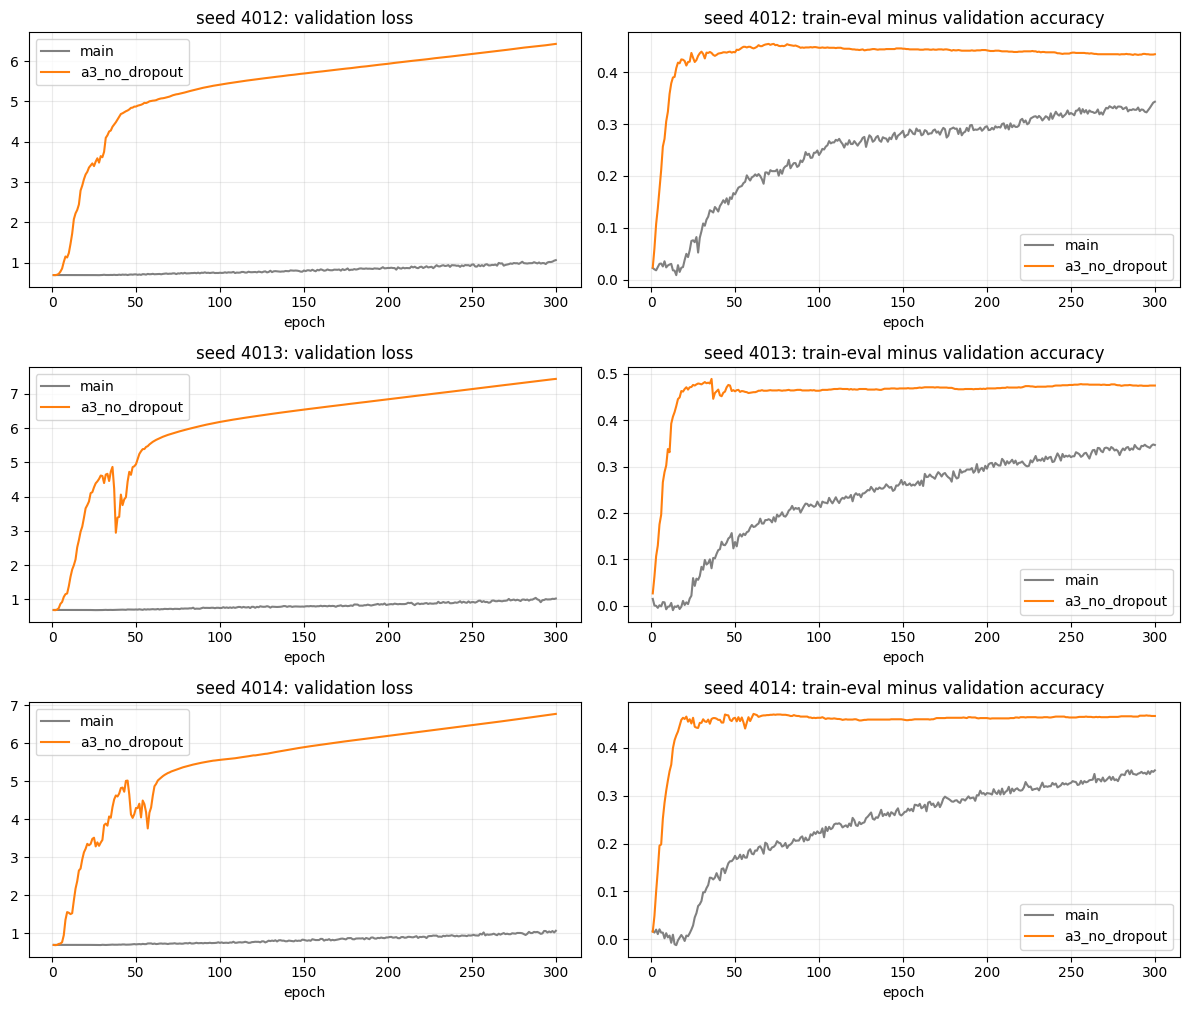

In [11]:
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(12, 3.4 * len(SEEDS)))
for row, seed in enumerate(SEEDS):
    for label, folder, colour in [('main', E2_DIR, 'grey'), ('a3_no_dropout', E4_DIR / 'a3_no_dropout', 'tab:orange')]:
        h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
        axes[row, 0].plot(h['epoch'], h['valid_loss'], color=colour, label=label)
        axes[row, 1].plot(h['epoch'], h['train_eval_accuracy'] - h['valid_accuracy'], color=colour, label=label)
    axes[row, 0].set_title(f'seed {seed}: validation loss')
    axes[row, 1].set_title(f'seed {seed}: train-eval minus validation accuracy')
    for ax in axes[row]:
        ax.set_xlabel('epoch'); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / 'a3_gap_loss.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
import platform
try:
    import torch
    torch_version, cuda_version = torch.__version__, torch.version.cuda
    device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
except ImportError:
    torch_version = cuda_version = device = 'not installed'
env = {'mode': 'training' if RUN_TRAINING else 'read saved logs',
       'python': platform.python_version(), 'torch': torch_version, 'cuda': cuda_version, 'device': device,
       'seeds': SEEDS, 'valid_rows': EXPECTED_VALID_ROWS,
       'repo_commit': E4_COMMIT, 'e2_commit': E2_COMMIT}
if RUN_TRAINING:
    # Training only: record the Colab environment of the new runs.
    freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
    (OUT_DIR / 'env_freeze.txt').write_text(freeze, encoding='utf-8')
    (OUT_DIR / 'env.json').write_text(json.dumps(env, indent=2), encoding='utf-8')
    print(env)
else:
    # Read mode: the environment record of the original runs (experiments/E4 updated/env.json) is kept as it is.
    # This line shows the machine that is running the notebook now, for reference only.
    print('Environment of the original runs: experiments/E4 updated/env.json (not overwritten in read mode).')
    print('This machine:', env)


Environment of the original runs: experiments/E4 updated/env.json (not overwritten in read mode).
This machine: {'mode': 'read saved logs', 'python': '3.11.15', 'torch': '2.14.0+cu130', 'cuda': '13.0', 'device': 'cpu', 'seeds': [4012, 4013, 4014], 'valid_rows': 1606, 'repo_commit': 'not recorded (no .git in this copy)', 'e2_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7'}


## 2.6 · Training summary (validation split)

One row per run, from the saved summaries and histories. Gaps are train-eval minus validation accuracy. Written to `training_summary.csv`. The paired comparison (Table 2) is in Section 3.

In [13]:
rows = []
for name in ['main'] + RUN_NAMES:
    folder = E2_DIR if name == 'main' else E4_DIR / name
    s = pd.read_csv(folder / 'm3_summary.csv')
    ends = [final_epoch(folder, int(seed)) for seed in SEEDS]
    rows.append({'run': name,
                 'valid_acc_mean': s['valid_accuracy'].mean(), 'valid_acc_sd': s['valid_accuracy'].std(),
                 'best_epoch_mean': s['best_epoch'].mean(), 'gap_at_best_mean': s['gap_at_best'].mean(),
                 'gap_at_end_mean': np.mean([e['gap_at_end'] for e in ends]),
                 'valid_loss_at_end_mean': np.mean([e['valid_loss_at_end'] for e in ends])})
training_summary = pd.DataFrame(rows).round(4)
training_summary.to_csv(OUT_DIR / 'training_summary.csv', index=False)
training_summary

,run,valid_acc_mean,valid_acc_sd,best_epoch_mean,gap_at_best_mean,gap_at_end_mean,valid_loss_at_end_mean
0,main,0.5940,0.0081,185.3333,0.2748,0.3474,1.0513
1,a1_no_position,0.5969,0.0050,183.3333,0.2644,0.3447,0.9469
2,a1_one_head,0.5863,0.0016,186.6667,0.2217,0.2798,0.9151
3,a3_no_dropout,0.5627,0.0121,10.6667,0.2549,0.4585,6.8791


**Figure 2 (comparison).** Validation accuracy of the main model and each ablation: mean over three seeds, with the sample standard deviation. The dashed line is chance (0.5; the two answer classes are balanced). Built from `training_summary`, the table written above.

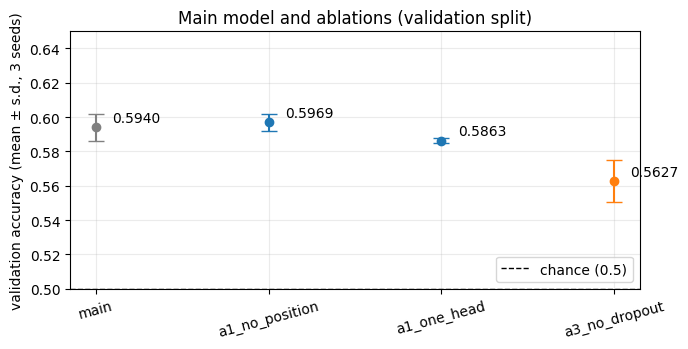

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colours = {'main': 'grey', 'a1_no_position': 'tab:blue', 'a1_one_head': 'tab:blue', 'a3_no_dropout': 'tab:orange'}
for x, row in enumerate(training_summary.itertuples()):
    ax.errorbar(x, row.valid_acc_mean, yerr=row.valid_acc_sd, fmt='o', capsize=6, color=colours.get(row.run, 'tab:blue'))
    ax.annotate(f'{row.valid_acc_mean:.4f}', (x, row.valid_acc_mean), textcoords='offset points', xytext=(12, 4))
ax.axhline(0.5, ls='--', color='black', lw=1, label='chance (0.5)')
ax.set_xticks(range(len(training_summary)), training_summary['run'], rotation=15)
ax.set_ylabel('validation accuracy (mean ± s.d., 3 seeds)')
ax.set_ylim(0.5, 0.65)
ax.set_title('Main model and ablations (validation split)')
ax.legend(loc='lower right'); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / 'valid_accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()